<a href="https://colab.research.google.com/github/itsabhi-21/Prognos/blob/main/notebooks/04_deep_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 4: Deep Sequence Models (LSTM, GRU, 1D-CNN)

**Goal:** Train neural networks on 30-cycle sensor windows and compare them with the untuned baselines from Notebook 3.

**Setup:** The windows from Notebook 3 are used as input; the target is the capped RUL (125). The hyperparameters are fixed here on purpose; tuning with Optuna follows in Notebook 5. Training uses early stopping on a validation set of held-out engines.

## 1. Setup and loading
Load the saved windows and the baseline results, and select the GPU if available.

In [1]:
import os, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from google.colab import drive

drive.mount('/content/drive')
PROC_DIR = '/content/drive/MyDrive/Prognos/processed'

SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']
CAP = 125
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

def set_seed(s=42):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

W = {fd: dict(np.load(f'{PROC_DIR}/windows_{fd}.npz')) for fd in SUBSETS}
baselines = pd.read_csv(f'{PROC_DIR}/baseline_results.csv')
print({fd: (W[fd]['X_train'].shape, W[fd]['X_test'].shape) for fd in SUBSETS})

Mounted at /content/drive
device: cuda
{'FD001': ((20631, 30, 14), (100, 30, 14)), 'FD002': ((53759, 30, 14), (259, 30, 14)), 'FD003': ((24720, 30, 15), (100, 30, 15)), 'FD004': ((61249, 30, 15), (248, 30, 15))}


## 2. Metrics
Same metrics as in Notebook 3: RMSE and the asymmetric NASA score (late predictions are penalised more; lower is better).

In [2]:
def rmse(y, p):
    return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

## 3. Model architectures
- **LSTM / GRU:** two recurrent layers read the 30-cycle window; the state after the last cycle goes through a small fully connected head that outputs one RUL value.
- **1D-CNN:** two convolution layers (kernel size 3) slide over the time axis, global average pooling summarises the window, then the same kind of head.
All models use dropout (0.2) against overfitting.

In [3]:
class RNNNet(nn.Module):
    def __init__(self, n_feat, cell='lstm', hidden=64, layers=2, dropout=0.2):
        super().__init__()
        rnn = nn.LSTM if cell == 'lstm' else nn.GRU
        self.rnn = rnn(n_feat, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        out, _ = self.rnn(x)
        return self.head(out[:, -1]).squeeze(-1)

class CNN1D(nn.Module):
    def __init__(self, n_feat, channels=64, dropout=0.2):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(n_feat, channels, 3, padding=1), nn.ReLU(),
            nn.Conv1d(channels, channels, 3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout),
                                  nn.Linear(channels, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x):
        return self.head(self.conv(x.transpose(1, 2))).squeeze(-1)   # (batch, features, time)

MODELS = {
    'LSTM': lambda n: RNNNet(n, 'lstm'),
    'GRU': lambda n: RNNNet(n, 'gru'),
    '1D-CNN': lambda n: CNN1D(n),
}

## 4. Training and prediction functions
- 20% of the training **engines** are held out for validation (engine-wise split, as in Notebook 3).
- Loss: mean squared error on the capped RUL; optimiser: Adam (learning rate 0.001); batch size 256.
- Early stopping: training stops when the validation RMSE has not improved for 8 epochs, and the best epoch is restored.
- Note: unlike the baselines, the final network is trained on 80% of the training engines (the other 20% steer early stopping).

In [4]:
def predict(model, X):
    model.eval()
    outs = []
    with torch.no_grad():
        for i in range(0, len(X), 2048):
            xb = torch.tensor(X[i:i + 2048], dtype=torch.float32).to(device)
            outs.append(model(xb).cpu())
    return torch.cat(outs).numpy()

def train_model(make_model, X, y, units, epochs=40, lr=1e-3, batch=256, patience=8, seed=42):
    set_seed(seed)
    tr_idx, va_idx = next(GroupShuffleSplit(1, test_size=0.2, random_state=42).split(X, groups=units))
    Xtr = torch.tensor(X[tr_idx], dtype=torch.float32)
    ytr = torch.tensor(y[tr_idx], dtype=torch.float32)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=batch, shuffle=True)

    model = make_model(X.shape[2]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    best, best_state, bad, hist = float('inf'), None, 0, []

    for ep in range(epochs):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        v = rmse(y[va_idx], predict(model, X[va_idx]))
        hist.append(v)
        if v < best - 1e-3:
            best, best_state, bad = v, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)
    return model, best, hist

## 5. Training all models on all subsets
Each model is trained once per subset (fixed seed) and evaluated on the last window of every test engine against the true RUL. As in Notebook 3, the RMSE against the capped truth is reported as well.

In [5]:
import time
results, histories, preds = [], {}, {}

for fd in SUBSETS:
    d = W[fd]
    for name, mk in MODELS.items():
        t0 = time.time()
        model, val_rmse, hist = train_model(mk, d['X_train'], d['y_train'], d['units_train'])
        p = predict(model, d['X_test'])
        y = d['y_test_true']
        results.append({'subset': fd, 'model': name,
                        'val_rmse': val_rmse,
                        'test_rmse': rmse(y, p),
                        'test_rmse_clipped_truth': rmse(np.minimum(y, CAP), p),
                        'nasa_score': nasa_score(y, p),
                        'epochs': len(hist)})
        histories[(fd, name)] = hist
        preds[(fd, name)] = p
        print(f'{fd} {name}: test RMSE {results[-1]["test_rmse"]:.2f} | epochs {len(hist)} | {time.time() - t0:.0f}s')

deep = pd.DataFrame(results).round(2)
deep.to_csv(f'{PROC_DIR}/deep_results.csv', index=False)
deep

FD001 LSTM: test RMSE 15.98 | epochs 15 | 16s
FD001 GRU: test RMSE 15.14 | epochs 20 | 7s
FD001 1D-CNN: test RMSE 19.67 | epochs 40 | 13s
FD002 LSTM: test RMSE 26.29 | epochs 12 | 15s
FD002 GRU: test RMSE 26.14 | epochs 12 | 12s
FD002 1D-CNN: test RMSE 30.27 | epochs 20 | 17s
FD003 LSTM: test RMSE 16.48 | epochs 21 | 9s
FD003 GRU: test RMSE 13.13 | epochs 24 | 11s
FD003 1D-CNN: test RMSE 22.01 | epochs 40 | 15s
FD004 LSTM: test RMSE 26.75 | epochs 12 | 13s
FD004 GRU: test RMSE 26.37 | epochs 15 | 16s
FD004 1D-CNN: test RMSE 31.33 | epochs 20 | 20s


,subset,model,val_rmse,test_rmse,test_rmse_clipped_truth,nasa_score,epochs
0,FD001,LSTM,11.96,15.98,15.19,721.18,15
1,FD001,GRU,11.33,15.14,14.12,486.33,20
2,FD001,1D-CNN,17.33,19.67,18.60,1556.59,40
3,FD002,LSTM,15.06,26.29,14.38,7354.83,12
4,FD002,GRU,14.72,26.14,13.98,7133.23,12
5,FD002,1D-CNN,19.07,30.27,17.97,13166.18,20
6,FD003,LSTM,11.38,16.48,15.02,955.90,21
7,FD003,GRU,10.14,13.13,11.48,274.67,24
8,FD003,1D-CNN,16.26,22.01,20.96,1875.84,40
9,FD004,LSTM,16.33,26.75,15.73,4779.07,12


## 6. Comparison with the baselines
Test RMSE and NASA score of all models side by side (lower is better).

Test RMSE


subset,FD001,FD002,FD003,FD004
model,,,,
Ridge,21.97,30.91,21.59,31.70
Random Forest,20.67,28.17,21.92,29.64
XGBoost,20.15,28.85,21.41,29.80
LSTM,15.98,26.29,16.48,26.75
GRU,15.14,26.14,13.13,26.37
1D-CNN,19.67,30.27,22.01,31.33


NASA score


subset,FD001,FD002,FD003,FD004
model,,,,
Ridge,1789.43,17289.00,1476.63,8296.53
Random Forest,1919.91,10512.00,2390.66,7242.79
XGBoost,1470.77,14263.84,2293.27,6883.54
LSTM,721.18,7354.83,955.90,4779.07
GRU,486.33,7133.23,274.67,4595.88
1D-CNN,1556.59,13166.18,1875.84,9168.80


Best model per subset (test RMSE):
{'FD001': 'GRU', 'FD002': 'GRU', 'FD003': 'GRU', 'FD004': 'GRU'}


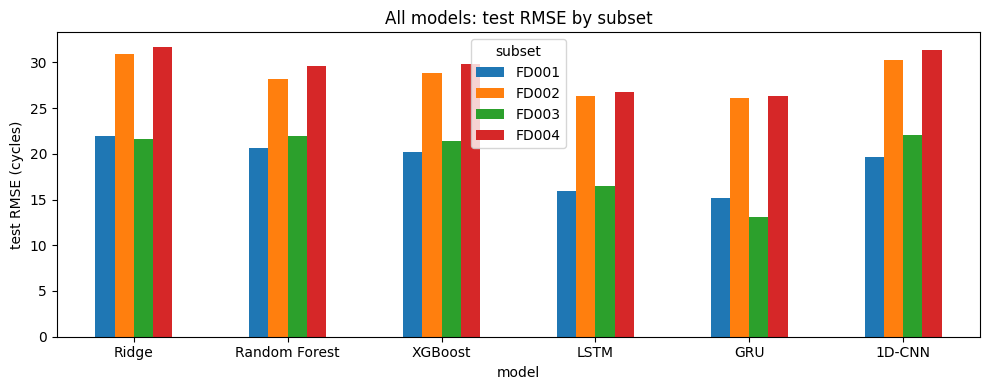

In [6]:
allres = pd.concat([baselines[baselines['model'] != 'Dummy (mean)'], deep], ignore_index=True)
order = ['Ridge', 'Random Forest', 'XGBoost', 'LSTM', 'GRU', '1D-CNN']

rm = allres.pivot(index='model', columns='subset', values='test_rmse').loc[order]
ns = allres.pivot(index='model', columns='subset', values='nasa_score').loc[order]
print('Test RMSE'); display(rm)
print('NASA score'); display(ns)
print('Best model per subset (test RMSE):'); print(rm.idxmin().to_dict())

rm.plot.bar(figsize=(10, 4))
plt.ylabel('test RMSE (cycles)'); plt.title('All models: test RMSE by subset'); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

## 7. Training curves
Validation RMSE per epoch for FD001. The curve shows whether the networks converge and when early stopping kicks in.

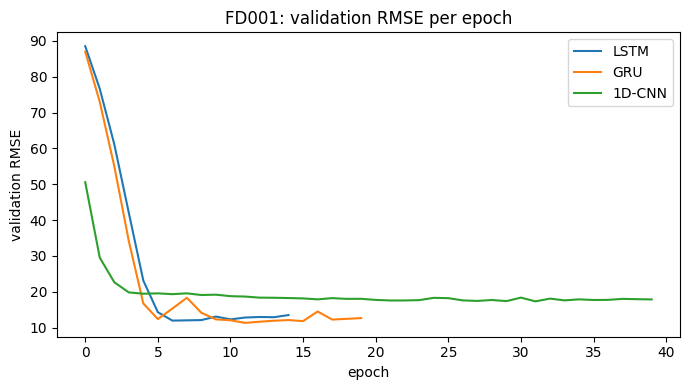

In [7]:
plt.figure(figsize=(7, 4))
for name in MODELS:
    plt.plot(histories[('FD001', name)], label=name)
plt.xlabel('epoch'); plt.ylabel('validation RMSE'); plt.title('FD001: validation RMSE per epoch')
plt.legend(); plt.tight_layout(); plt.show()

## 8. Predicted vs. true RUL (best deep model per subset)
Each point is one test engine. Points on the diagonal are perfect predictions; points above it are over-estimates of the remaining life (late warnings, the dangerous case).

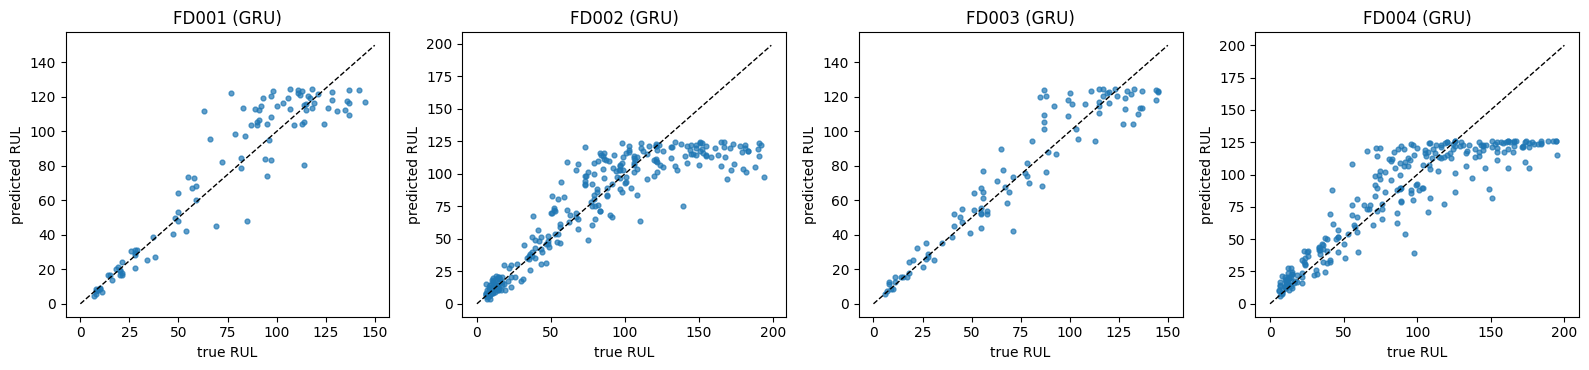

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, fd in zip(axes, SUBSETS):
    best = deep[deep['subset'] == fd].sort_values('test_rmse').iloc[0]['model']
    y, p = W[fd]['y_test_true'], preds[(fd, best)]
    ax.scatter(y, p, s=12, alpha=0.7)
    lim = max(y.max(), p.max()) + 5
    ax.plot([0, lim], [0, lim], 'k--', lw=1)
    ax.set_title(f'{fd} ({best})'); ax.set_xlabel('true RUL'); ax.set_ylabel('predicted RUL')
plt.tight_layout(); plt.show()

## 9. Key findings

- **GRU is the best model on all four subsets:** test RMSE 15.14 (FD001), 26.14 (FD002), 13.13 (FD003) and 26.37 (FD004). Compared with the best untuned baseline this is a reduction of about 25%, 7%, 39% and 11%.
- **NASA score improves as well:** GRU reaches 486, 7,133, 275 and 4,596 versus 1,471, 10,512, 1,477 and 6,884 for the best baselines, meaning fewer and smaller late predictions.
- **LSTM is close behind GRU:** the difference is below 1 RMSE point on FD001, FD002 and FD004, which is likely within seed-to-seed noise (single run); only FD003 shows a clear gap (13.13 vs 16.48). Multiple seeds will be used in Notebook 5 before ranking the two.
- **The 1D-CNN is not better than the tree baselines:** 19.67, 30.27, 22.01 and 31.33. The global average pooling discards the temporal order within the window, which matters for RUL; a flatten or last-step design will be tested during tuning.
- **Training behaviour:** LSTM and GRU converge within about 5 epochs (validation RMSE from about 88 to about 12 on FD001) and early stopping triggers after 12-24 epochs; the CNN plateaus around 18 and runs all 40 epochs.
- **Multi-condition subsets stay harder:** FD002 and FD004 have test RMSE of about 26 versus 13-15 for FD001 and FD003. Against the capped truth the GRU RMSE is only 14.0 (FD002) and 15.4 (FD004), so most of the gap comes from engines with a true RUL up to about 195, where predictions saturate near the cap of 125.
- **Error pattern:** Predictions follow the diagonal closely for true RUL below about 50 cycles, the range that matters most for maintenance decisions. Over-estimates (late warnings) appear at medium RUL, for example in FD003 (true RUL about 85, predicted about 120).
- **Caveats:** All results come from a single seed and from networks trained on 80% of the training engines (baselines were refitted on all of them), with fixed untuned hyperparameters.
- **Next step:** Tune the GRU/LSTM (and an improved CNN) with Optuna, repeat over several seeds, compare with published results using the same evaluation convention, and analyse errors.